# Día 1 — Componentes de una serie y pronósticos simples

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 04-11-2026 · **Unidad 1. Series de Tiempo**

En el Módulo 3 la regla fue **pregunta → datos → exploración → preparación → modelo → métricas → diagnóstico → decisión**. Hoy la aplicamos a una serie de tiempo, con una diferencia que cambia todo: **las filas tienen un orden y el pasado es la única información disponible para predecir el futuro**.

La pregunta conductora de todo el módulo es:

> **¿Cuál será la inflación mensual del Ecuador en los próximos meses?**

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- qué representa una fila y cuál es la **frecuencia** de una serie (1.1);
- qué son **tendencia, estacionalidad y variaciones atípicas**, y cómo separarlas con una **descomposición** (1.2);
- qué es un **rezago** y qué mide la **autocorrelación**, calculada primero a mano (1.3);
- cómo funcionan los pronósticos **ingenuo, ingenuo estacional, promedio móvil y media histórica** (1.4);
- por qué un pronóstico simple es la **línea base** que todo modelo debe superar.

## Cómo está organizado

Seguimos los mismos pasos del Módulo 3:

1. Mirar la serie y graficarla.
2. Preparar paso a paso.
3. Línea base.
4. El método a mano, con números pequeños.
5. La versión simple con la librería.
6. Métricas a mano y con la librería, Train frente a Validation.
7. Hiperparámetros uno por uno y un `for`.
8. Resultado final con Test, una sola vez.
9. Comparación final en varias series.

## 0. Librerías que usaremos

Hoy aparece una librería nueva: **statsmodels**, especializada en estadística y econometría. Si no está instalada, ejecuta en una celda nueva:

```python
%pip install statsmodels
```

y reinicia el kernel.

In [1]:
# Cálculo numérico y datos tabulares
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Rutas de archivos
from pathlib import Path

# Series de tiempo
from statsmodels.tsa.seasonal import seasonal_decompose, STL   # descomposición
from statsmodels.tsa.stattools import acf                       # autocorrelación
from statsmodels.graphics.tsaplots import plot_acf              # gráfico de autocorrelación

# Métricas (las mismas del Módulo 3)
from sklearn.metrics import mean_absolute_error, mean_squared_error

### ¿Qué aporta cada import?

- `seasonal_decompose` y `STL` separan una serie en tendencia, estacionalidad y residuo;
- `acf` calcula la autocorrelación y `plot_acf` la dibuja;
- `mean_absolute_error` y `mean_squared_error` son las métricas que ya usamos en regresión. **Un pronóstico es una predicción numérica**, así que se evalúa igual.

In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('datos') if Path('datos').exists() else Path('../datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


# 1. La serie conductora: inflación mensual del Ecuador

Usaremos `datos/series_economicas.csv`, con datos oficiales del **INEC** y del **BCE**. La columna principal es:

| Columna | Qué mide | Unidad |
|---|---|---|
| `ipc_var_mensual` | variación del Índice de Precios al Consumidor respecto al mes anterior | % |

Una inflación mensual de 0.30 significa que, en promedio, los precios de la canasta subieron 0.30 % frente al mes anterior. Un valor negativo significa que bajaron.

In [3]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha')
series = series.asfreq('MS')   # un registro por mes, como en el Día 0

series[['ipc_indice', 'ipc_var_mensual']].dropna().tail()

,ipc_indice,ipc_var_mensual
fecha,,
2026-04-01,100.721137,0.525567
2026-05-01,100.095395,-0.621261
2026-06-01,100.884870,0.788722
2026-07-01,100.794745,-0.089334
2026-08-01,100.838024,0.042938


## 1.1 Estructura y frecuencia

Antes de calcular nada respondemos tres preguntas:

- **¿Qué representa una fila?** Un mes del calendario.
- **¿Cuál es la frecuencia?** Mensual: 12 observaciones por año.
- **¿Qué periodo usaremos?** El Día 0 vimos que antes de 2001 la economía tenía hiperinflación. Usaremos **desde enero de 2005**, cuando la inflación ya se había estabilizado tras la dolarización.

In [4]:
# Seleccionamos la serie y el periodo de trabajo.
y = series['ipc_var_mensual'].loc['2005':].dropna()

print('Observaciones:', len(y))
print('Desde:', y.index.min().strftime('%b %Y'), '· Hasta:', y.index.max().strftime('%b %Y'))
print('Frecuencia:', y.index.freqstr)
print('Años completos:', len(y) // 12)

Observaciones: 260
Desde: Jan 2005 · Hasta: Aug 2026
Frecuencia: MS
Años completos: 21


Tenemos **260 meses**. En el Módulo 3 una fila era un cliente y podíamos tener miles; aquí cada fila cuesta un mes de espera. Por eso en series de tiempo los datos son "pocos" aunque cubran 21 años, y cada observación vale mucho.

## 1.2 Mirar los números antes de graficar

In [5]:
y.describe().round(3)

count    260.000
mean       0.212
std        0.368
min       -0.986
25%       -0.005
50%        0.173
75%        0.399
max        1.518
Name: ipc_var_mensual, dtype: float64

### Cómo leer `describe()` en esta serie

- `mean ≈ 0.21`: en promedio los precios subieron 0.21 % al mes desde 2005 (aproximadamente 2.6 % al año).
- `std ≈ 0.37`: la variación típica alrededor de la media es mayor que la propia media; hay mucho ruido mes a mes.
- `min ≈ −0.99` y `max ≈ 1.52`: hay meses muy alejados del centro que debemos revisar.

In [6]:
# Los cinco meses con mayor y menor inflación.
extremos = pd.concat([y.nlargest(5), y.nsmallest(5)]).round(2)
extremos.index = extremos.index.strftime('%b %Y')
extremos

fecha
Apr 2008    1.52
Mar 2008    1.48
Apr 2024    1.27
Jan 2008    1.14
Sep 2012    1.12
Dec 2024   -0.99
Jun 2024   -0.95
Nov 2019   -0.70
May 2026   -0.62
Jun 2020   -0.62
Name: ipc_var_mensual, dtype: float64

### ¿Por qué mirar los extremos?

Igual que en el Módulo 3, un promedio puede esconderlos. Aquí nos preguntamos **qué pasó en la economía** en esos meses:

- **2008**: alza mundial de precios de alimentos y combustibles.
- **abril 2024**: entra en vigor el aumento del IVA del 12 % al 15 %.
- **noviembre 2019**: el mes siguiente a la eliminación y posterior restitución del subsidio a los combustibles (octubre de 2019).

No son errores de captura: son **datos genuinos** que reflejan hechos económicos. No los borramos; los entendemos.

## 1.3 Graficar

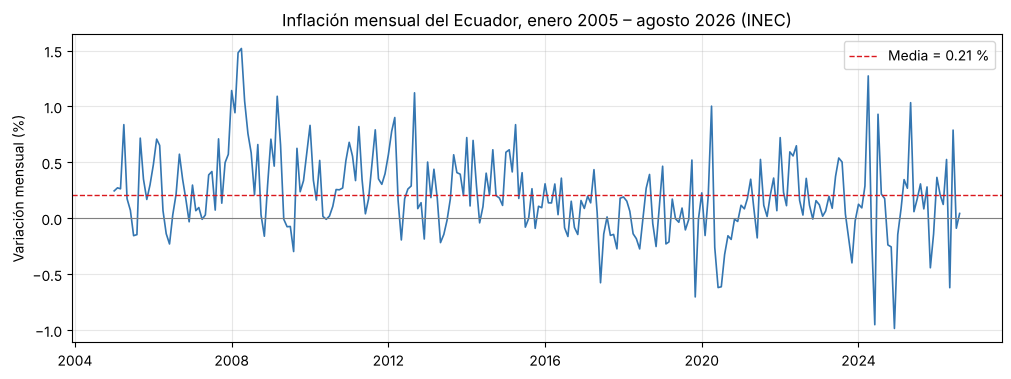

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(y, color='#3476B1', linewidth=1.2)
ax.axhline(0, color='gray', linewidth=0.8)
ax.axhline(y.mean(), color='#DA181E', linestyle='--', linewidth=1, label=f'Media = {y.mean():.2f} %')

ax.set_ylabel('Variación mensual (%)')
ax.set_title('Inflación mensual del Ecuador, enero 2005 – agosto 2026 (INEC)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Qué preguntarnos al ver la serie

- ¿Sube o baja en el largo plazo? → **tendencia**
- ¿Hay picos que se repiten en los mismos meses del año? → **estacionalidad**
- ¿Hay puntos aislados muy lejos del resto? → **variaciones atípicas**
- ¿El ruido de un mes a otro es grande comparado con esos patrones? → **residuo**

A simple vista hay periodos de inflación más alta (2008, 2022) y más baja (2017–2020), mucho ruido y algunos picos. Para separar esas piezas de forma ordenada usaremos una descomposición.

# 2. Tendencia, estacionalidad y variaciones atípicas (1.2)

Una serie de tiempo se puede pensar como la suma de tres componentes:

$$
y_t = T_t + S_t + R_t
$$

| Componente | Símbolo | Qué representa | Ejemplo en la inflación |
|---|---|---|---|
| Tendencia | $T_t$ | el nivel de fondo que cambia lentamente | inflación más alta en 2008 y 2022 |
| Estacionalidad | $S_t$ | un patrón que se repite cada año | inicio del año escolar, feriados |
| Residuo | $R_t$ | lo que no explican los dos anteriores | choques, cambios de impuestos, ruido |

A esto se le llama **modelo aditivo**. Si la estacionalidad creciera proporcionalmente con el nivel de la serie, usaríamos un modelo **multiplicativo** ($y_t = T_t \times S_t \times R_t$). Para una variación porcentual, que oscila alrededor de cero, el modelo aditivo es el adecuado.

## 2.1 La estacionalidad a simple vista

Antes de cualquier método, agrupemos por mes del año: si hay estacionalidad, algunos meses tendrán sistemáticamente más inflación que otros.

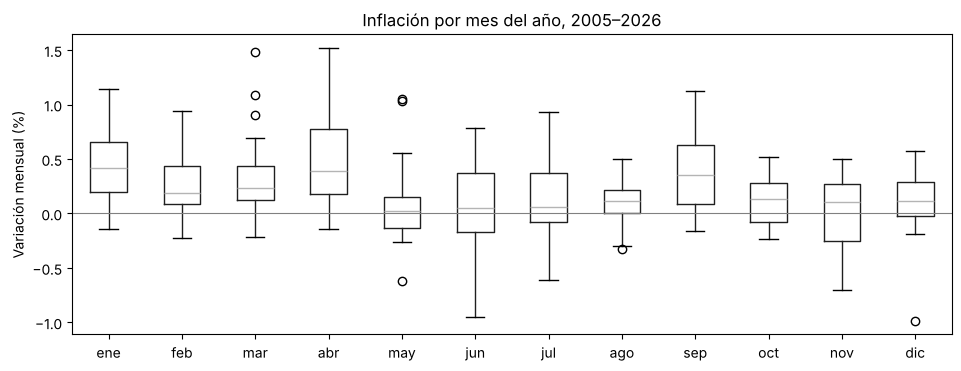

ene    0.42
feb    0.27
mar    0.36
abr    0.49
may    0.08
jun    0.05
jul    0.14
ago    0.10
sep    0.37
oct    0.12
nov    0.01
dic    0.11


In [8]:
nombres_mes = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']

por_mes = pd.DataFrame({'inflacion': y, 'mes': y.index.month})

fig, ax = plt.subplots(figsize=(11, 4))
por_mes.boxplot(column='inflacion', by='mes', ax=ax, grid=False)
ax.set_xticklabels(nombres_mes)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel('')
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Inflación por mes del año, 2005–2026')
plt.suptitle('')
plt.show()

print(por_mes.groupby('mes')['inflacion'].mean().round(2).set_axis(nombres_mes).to_string())

Cada caja resume los 21–22 valores de un mismo mes. Se observan medianas más altas en **enero, abril y septiembre** y más bajas de **mayo a julio**. Los promedios impresos debajo cuentan la misma historia, aunque se mueven más por los meses extremos.

Una explicación razonable: septiembre coincide con el **inicio del año escolar en la Sierra** (matrículas, útiles, uniformes) y abril con el de la **Costa**. Es una hipótesis que la descomposición nos ayudará a cuantificar.

## 2.2 Descomposición a mano, paso a paso

La descomposición clásica tiene tres pasos.

**Paso 1. Tendencia: promedio móvil centrado de 12 meses.**

Un promedio de 12 meses contiene exactamente un año, así que la estacionalidad se cancela. Como 12 es par, el centro cae entre dos meses; por eso se promedian dos promedios de 12 consecutivos (se llama promedio móvil **2×12**):

$$
T_t = \frac{1}{12}\left(\tfrac{1}{2}y_{t-6} + y_{t-5} + \dots + y_{t+5} + \tfrac{1}{2}y_{t+6}\right)
$$

Esta ventana mira 6 meses hacia adelante: **sirve para describir el pasado, no para pronosticar** (Día 0, `center=True`).

In [9]:
# Paso 1: promedio móvil de 12, luego promedio de 2 y centrado (desplazado 6 meses).
tendencia = y.rolling(12).mean().rolling(2).mean().shift(-6)

# Los primeros y últimos 6 meses quedan sin tendencia: no hay suficientes vecinos.
print('Meses con tendencia:', tendencia.notna().sum(), 'de', len(y))
tendencia.dropna().head(3).round(3)

Meses con tendencia: 248 de 260


fecha
2005-07-01    0.268
2005-08-01    0.295
2005-09-01    0.330
Freq: MS, Name: ipc_var_mensual, dtype: float64

**Paso 2. Quitar la tendencia y promediar por mes del año.**

Lo que queda después de restar la tendencia ($y_t - T_t$) contiene estacionalidad y residuo. Si promediamos todos los eneros, todos los febreros, etc., el residuo tiende a cancelarse y queda el **factor estacional** de cada mes. Finalmente se ajustan los 12 factores para que sumen cero.

In [10]:
# Paso 2a: serie sin tendencia.
sin_tendencia = y - tendencia

# Paso 2b: promedio por mes del año.
factor = sin_tendencia.groupby(sin_tendencia.index.month).mean()

# Paso 2c: centrar los factores para que sumen cero.
factor = factor - factor.mean()

factores = pd.DataFrame({'factor_estacional': factor.round(3).values}, index=nombres_mes)
print('Suma de los factores:', round(factor.sum(), 10))
factores.T

Suma de los factores: 0.0


,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
factor_estacional,0.222,0.055,0.162,0.26,-0.099,-0.201,-0.063,-0.109,0.158,-0.09,-0.197,-0.099


### Interpretar un factor estacional

El factor de **septiembre ≈ 0.16** significa que, descontando la tendencia, la inflación de septiembre suele estar **0.16 puntos porcentuales por encima** del promedio del año. El de **noviembre ≈ −0.20** indica lo contrario.

**Paso 3. Residuo:** lo que sobra.

$$
R_t = y_t - T_t - S_t
$$

In [11]:
# Paso 3: asignamos a cada mes su factor estacional y calculamos el residuo.
estacional = pd.Series(factor.loc[y.index.month].values, index=y.index)
residuo = y - tendencia - estacional

descomposicion_mano = pd.DataFrame({
    'observado': y, 'tendencia': tendencia, 'estacional': estacional, 'residuo': residuo
})
descomposicion_mano.loc['2024-01':'2024-06'].round(3)

,observado,tendencia,estacional,residuo
fecha,,,,
2024-01-01,0.125,0.116,0.222,-0.212
2024-02-01,0.093,0.120,0.055,-0.082
2024-03-01,0.288,0.114,0.162,0.012
2024-04-01,1.273,0.117,0.260,0.897
2024-05-01,-0.119,0.120,-0.099,-0.140
2024-06-01,-0.952,0.086,-0.201,-0.837


Comprueba una fila: en abril de 2024, observado = tendencia + estacional + residuo. El residuo de ese mes es grande y positivo: es el aumento del IVA, que no forma parte ni de la tendencia ni del patrón habitual de abril.

## 2.3 La misma descomposición con `seasonal_decompose`

`statsmodels` aplica exactamente los mismos tres pasos.

Diferencia máxima en la tendencia: 2.220446049250313e-16
Diferencia máxima en la estacionalidad: 0.0


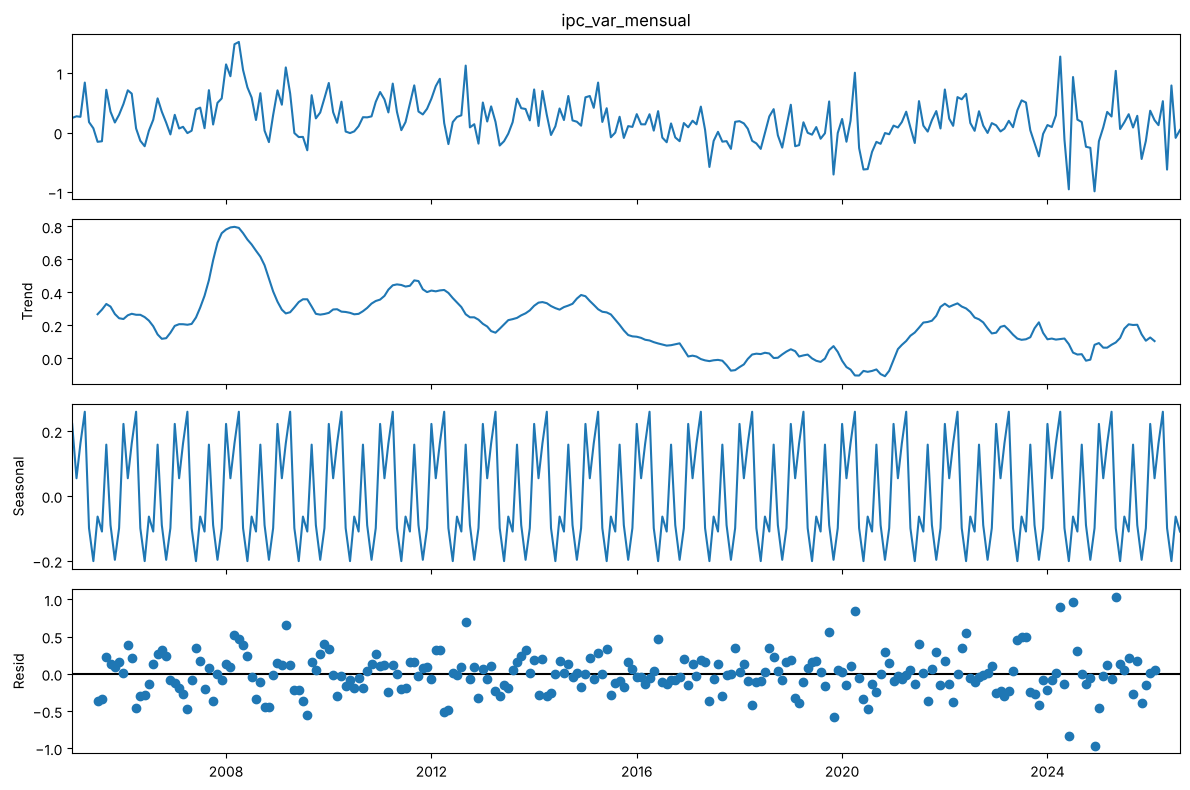

In [12]:
# model='additive' porque la serie oscila alrededor de cero.
# period=12 porque el patrón se repite cada 12 meses.
desc = seasonal_decompose(y, model='additive', period=12)

# Comprobamos que coincide con el cálculo a mano.
print('Diferencia máxima en la tendencia:', (desc.trend - tendencia).abs().max())
print('Diferencia máxima en la estacionalidad:', (desc.seasonal - estacional).abs().max().round(12))

fig = desc.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

### Lectura del gráfico

- **Trend:** máximos alrededor de 2008 y de 2022, mínimo entre 2017 y 2020 (incluso con tendencia negativa). La inflación de fondo **no es constante**.
- **Seasonal:** el mismo patrón se repite cada año; por construcción, la descomposición clásica obliga a que sea idéntico todos los años.
- **Resid:** la mayor parte es ruido pequeño, pero aparecen picos aislados.

## 2.4 Una alternativa más flexible: STL

La descomposición clásica tiene dos límites: no da tendencia en los 6 primeros y últimos meses, y supone que la estacionalidad nunca cambia. **STL** (*Seasonal-Trend decomposition using LOESS*) permite que la estacionalidad evolucione y, con `robust=True`, reduce la influencia de los valores atípicos.

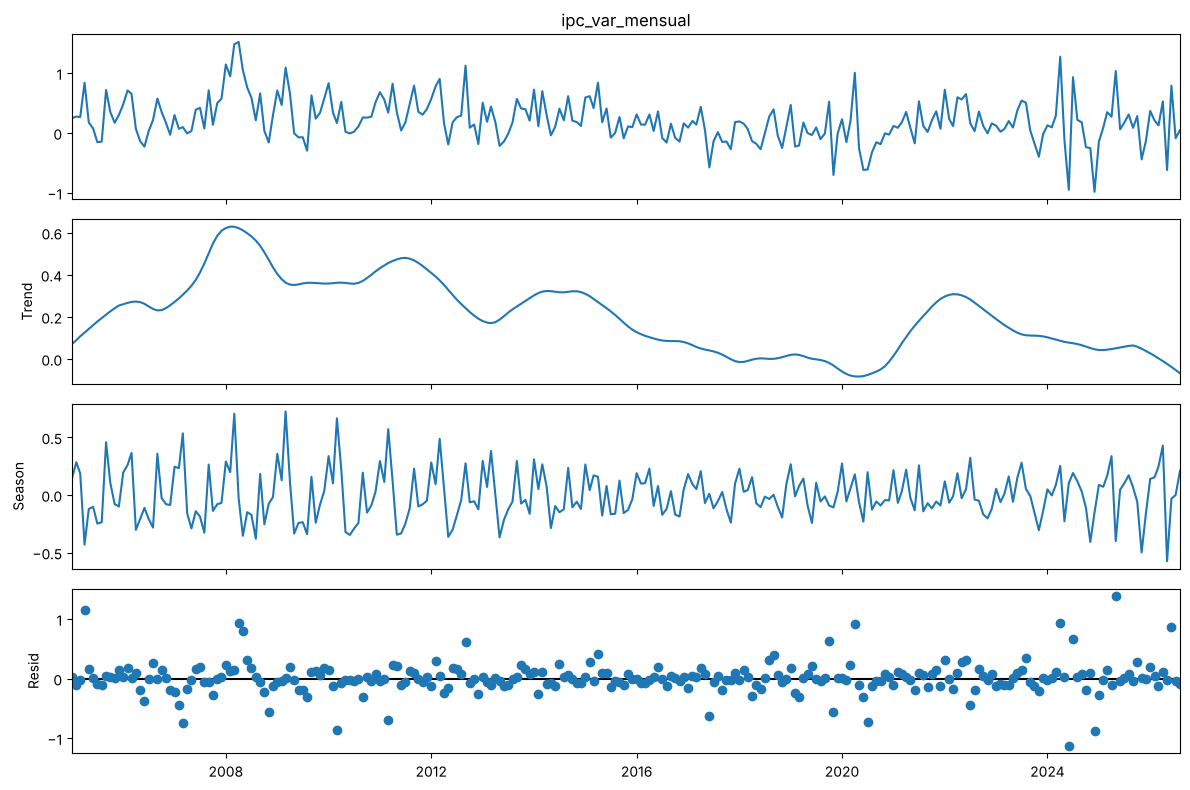

In [13]:
stl = STL(y, period=12, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

### Parámetros de `STL`, uno por uno

| Parámetro | Qué hace | Valor usado |
|---|---|---|
| `period` | longitud del ciclo estacional | 12 meses |
| `seasonal` | suavidad de la estacionalidad: más grande, más estable entre años | 7 (por defecto) |
| `robust` | da menos peso a los atípicos al estimar tendencia y estacionalidad | `True` |

Con STL la tendencia llega hasta el último mes y la estacionalidad cambia ligeramente entre años. **No hay una descomposición "verdadera"**: son dos formas razonables de mirar la misma serie.

## 2.5 Variaciones atípicas

Un valor atípico es uno que se aleja mucho de lo esperado. Usamos dos criterios:

1. **Rango intercuartílico (IQR)** sobre la serie original, como en el Módulo 3.
2. **Residuo estandarizado** de la descomposición: un residuo a más de 2.5 desviaciones estándar es "sorprendente" incluso después de considerar tendencia y estacionalidad.

In [14]:
# Criterio 1: IQR sobre la serie original.
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
atipicos_iqr = y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]

# Criterio 2: residuo estandarizado de la descomposición clásica.
r = desc.resid.dropna()
z = (r - r.mean()) / r.std()
atipicos_residuo = y[z[z.abs() > 2.5].index]

print('Atípicos por IQR:', len(atipicos_iqr))
print('Atípicos por residuo:', len(atipicos_residuo))
atipicos_residuo.round(2).rename(index=lambda f: f.strftime('%b %Y'))

Atípicos por IQR: 14
Atípicos por residuo: 7


fecha
Sep 2012    1.12
Apr 2020    1.00
Apr 2024    1.27
Jun 2024   -0.95
Jul 2024    0.93
Dec 2024   -0.99
May 2025    1.03
Name: ipc_var_mensual, dtype: float64

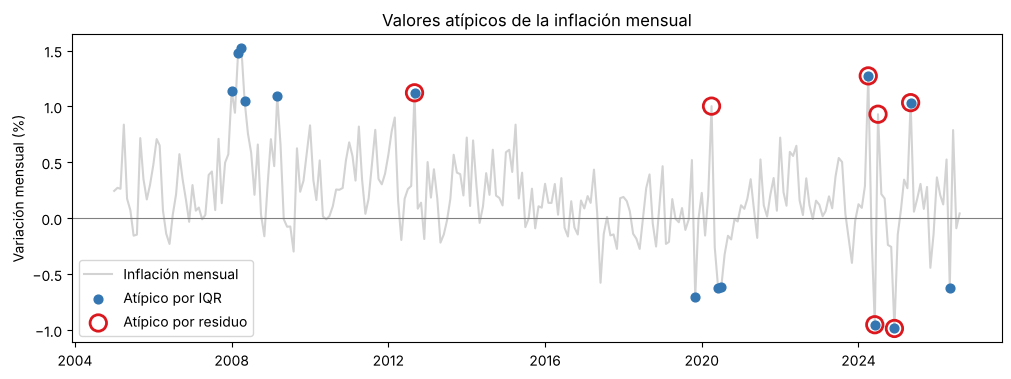

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y, color='lightgray', label='Inflación mensual')
ax.scatter(atipicos_iqr.index, atipicos_iqr, color='#3476B1', s=40, label='Atípico por IQR', zorder=3)
ax.scatter(atipicos_residuo.index, atipicos_residuo, facecolors='none', edgecolors='#DA181E',
           s=140, linewidth=2, label='Atípico por residuo', zorder=4)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Valores atípicos de la inflación mensual')
ax.legend()
plt.show()

### Dos criterios, dos respuestas

- El **IQR** marca los meses de 2008: son altos frente a toda la serie, pero coherentes con su época (la tendencia también era alta).
- El **residuo** marca meses que sorprenden **incluso conociendo la tendencia y el mes del año**. Varios están en 2024 y 2025.

**Lo que haremos con ellos:** por ahora, nada. Un pronóstico debe convivir con choques reales. Lo que sí sabemos es que esos meses **elevarán el error** de cualquier método, y que 2024 es un año poco típico. Lo veremos en la sección 5.

> **Pregunta para investigar:** ¿qué ocurrió en junio, julio y diciembre de 2024? Busca en los boletines del INEC qué divisiones de consumo explican esas variaciones.

# 3. Dependencia temporal, rezagos y autocorrelación (1.3)

En el Módulo 3 suponíamos que las filas eran **independientes**: lo que le pasa a un cliente no depende del cliente anterior. En una serie de tiempo esto casi nunca se cumple: **lo que pasó el mes pasado ayuda a predecir este mes**. Esa dependencia es la que aprovechan todos los métodos de pronóstico.

## 3.1 Rezagos y diagrama de dispersión

Con `shift` (Día 0) ponemos en la misma fila el valor de este mes y el del mes anterior.

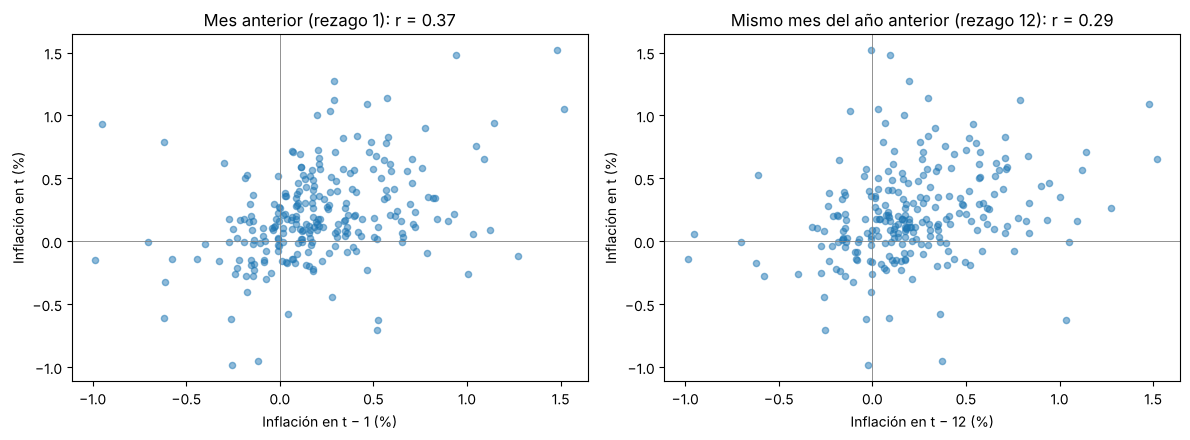

In [16]:
rezagos = pd.DataFrame({
    'y_t': y,
    'y_t_menos_1': y.shift(1),
    'y_t_menos_12': y.shift(12),
}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, titulo in zip(axes, ['y_t_menos_1', 'y_t_menos_12'],
                           ['Mes anterior (rezago 1)', 'Mismo mes del año anterior (rezago 12)']):
    ax.scatter(rezagos[col], rezagos['y_t'], alpha=0.5, s=20)
    r = rezagos['y_t'].corr(rezagos[col])
    ax.set_xlabel(f'Inflación en t − {col.split("_")[-1]} (%)')
    ax.set_ylabel('Inflación en t (%)')
    ax.set_title(f'{titulo}: r = {r:.2f}')
    ax.axhline(0, color='gray', linewidth=0.6); ax.axvline(0, color='gray', linewidth=0.6)
plt.tight_layout()
plt.show()

Cada punto compara un mes con un mes anterior. Si los puntos suben hacia la derecha, meses con inflación alta suelen venir después de meses con inflación alta. La correlación es **positiva pero moderada**: el pasado ayuda, pero no determina el presente.

## 3.2 Autocorrelación a mano

La **autocorrelación de rezago $k$** es la correlación de una serie consigo misma desplazada $k$ periodos:

$$
r_k = \frac{\sum_{t=k+1}^{n}(y_t-\bar y)(y_{t-k}-\bar y)}{\sum_{t=1}^{n}(y_t-\bar y)^2}
$$

Usemos seis valores pequeños: $y = [1, 2, 3, 5, 4, 6]$, con media $\bar y = 21/6 = 3.5$.

| $t$ | $y_t$ | $y_t-\bar y$ | $(y_t-\bar y)^2$ | $(y_t-\bar y)(y_{t-1}-\bar y)$ |
|---:|---:|---:|---:|---:|
| 1 | 1 | −2.5 | 6.25 | — |
| 2 | 2 | −1.5 | 2.25 | (−1.5)(−2.5) = 3.75 |
| 3 | 3 | −0.5 | 0.25 | (−0.5)(−1.5) = 0.75 |
| 4 | 5 | 1.5 | 2.25 | (1.5)(−0.5) = −0.75 |
| 5 | 4 | 0.5 | 0.25 | (0.5)(1.5) = 0.75 |
| 6 | 6 | 2.5 | 6.25 | (2.5)(0.5) = 1.25 |
| **Suma** | | | **17.50** | **5.75** |

$$
r_1 = \frac{5.75}{17.50} = 0.329
$$

Una autocorrelación positiva: cuando un valor está sobre la media, el siguiente también tiende a estarlo.

In [17]:
mini = np.array([1, 2, 3, 5, 4, 6])
media = mini.mean()
desv = mini - media

numerador = np.sum(desv[1:] * desv[:-1])   # productos de cada valor con el anterior
denominador = np.sum(desv ** 2)

print('Numerador:', numerador)
print('Denominador:', denominador)
print('r1 a mano:', round(numerador / denominador, 3))

# statsmodels usa la misma fórmula.
print('r1 con acf():', round(acf(mini, nlags=1)[1], 3))

Numerador: 5.75
Denominador: 17.5
r1 a mano: 0.329
r1 con acf(): 0.329


> **Detalle:** `pandas.Series.autocorr()` calcula una correlación de Pearson entre las partes superpuestas, con medias distintas para cada parte. Da valores parecidos pero no idénticos. En este módulo usaremos `acf()`, que es la definición estándar en series de tiempo.

## 3.3 La función de autocorrelación (ACF) de la inflación

Calcular $r_k$ para $k = 1, 2, \dots, 24$ y graficarlos da la **ACF**. Las bandas sombreadas indican hasta dónde una autocorrelación podría ser solo azar (aproximadamente $\pm 1.96/\sqrt{n}$).

Banda aproximada: ±0.122
        1      2      3     4      5      6      7      8      9     10     11     12
r_k  0.363  0.213  0.178  0.08  0.044  0.179  0.086  0.084  0.124  0.17  0.181  0.276


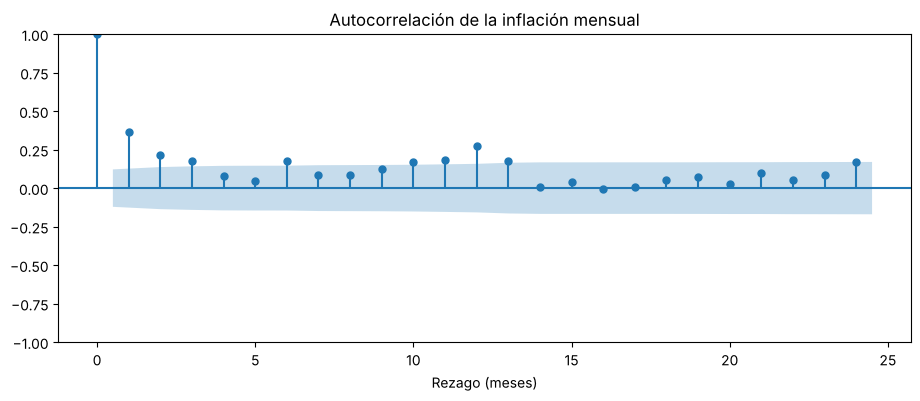

In [18]:
autocorr = acf(y, nlags=24)
banda = 1.96 / np.sqrt(len(y))

print(f'Banda aproximada: ±{banda:.3f}')
print(pd.Series(autocorr[1:13], index=range(1, 13)).round(3).to_frame('r_k').T.to_string())

fig, ax = plt.subplots(figsize=(11, 4))
plot_acf(y, lags=24, ax=ax)
ax.set_xlabel('Rezago (meses)')
ax.set_title('Autocorrelación de la inflación mensual')
plt.show()

### Interpretación

- **Rezago 1 ≈ 0.36**: la autocorrelación más fuerte. El mes pasado es la mejor pista individual.
- **Rezagos 2 y 3** siguen fuera de la banda: la dependencia dura algunos meses y se debilita.
- **Rezago 12 ≈ 0.28**: vuelve a subir. Es la huella de la **estacionalidad** vista en la sección 2.
- Muchos rezagos intermedios quedan cerca o dentro de la banda.

**Conclusión:** la inflación tiene memoria corta y un patrón anual. Los dos pronósticos simples más naturales serán, entonces, **"como el mes pasado"** (rezago 1) y **"como el mismo mes del año pasado"** (rezago 12). El Día 2 usaremos la ACF para elegir modelos AR y MA.

# 4. Pronósticos simples (1.4)

Un pronóstico simple usa una regla fija en lugar de un modelo estimado. Son la **línea base** del módulo: si un ARIMA o un Random Forest no los supera, no vale la pena usarlo.

| Método | Regla para el mes $t+1$ | Qué supone |
|---|---|---|
| **Ingenuo** | $\hat y_{t+1} = y_t$ | el próximo mes será como el último |
| **Ingenuo estacional** | $\hat y_{t+1} = y_{t+1-12}$ | como el mismo mes del año anterior |
| **Promedio móvil de $k$** | $\hat y_{t+1} = \frac{1}{k}\sum_{i=0}^{k-1} y_{t-i}$ | como el promedio de los últimos $k$ meses |
| **Media histórica** | $\hat y_{t+1} = \frac{1}{t}\sum_{i=1}^{t} y_i$ | como el promedio de todo el pasado |

Todos usan **solo información anterior** al mes que pronostican.

## 4.1 A mano: pronosticar julio de 2024

Conocemos la inflación hasta junio de 2024:

| Mes | ene | feb | mar | abr | may | jun | | jul 2023 |
|---|---:|---:|---:|---:|---:|---:|---|---:|
| Inflación (%) | 0.13 | 0.09 | 0.29 | 1.27 | −0.12 | −0.95 | | 0.54 |

| Método | Cálculo | Pronóstico jul-2024 |
|---|---|---:|
| Ingenuo | último valor (junio) | −0.95 |
| Ingenuo estacional | julio de 2023 | 0.54 |
| Promedio móvil 3 | (1.27 − 0.12 − 0.95) / 3 | 0.07 |
| Media de 2024 | (0.13 + 0.09 + 0.29 + 1.27 − 0.12 − 0.95) / 6 | 0.12 |

La inflación real de julio de 2024 fue **0.93 %**. El error de cada método:

| Método | Error = real − pronóstico | Error absoluto |
|---|---:|---:|
| Ingenuo | 0.93 − (−0.95) = 1.88 | 1.88 |
| Ingenuo estacional | 0.93 − 0.54 = 0.39 | **0.39** |
| Promedio móvil 3 | 0.93 − 0.07 = 0.86 | 0.86 |
| Media de 2024 | 0.93 − 0.12 = 0.81 | 0.81 |

En este mes ganó el ingenuo estacional. **Un solo mes no basta para decidir**: necesitamos medir muchos meses.

In [19]:
# Comprobamos los cálculos a mano.
hasta_junio = y.loc[:'2024-06']

print('Ingenuo:', round(hasta_junio.iloc[-1], 2))
print('Ingenuo estacional:', round(y.loc['2023-07-01'], 2))
print('Promedio móvil 3:', round(hasta_junio.iloc[-3:].mean(), 2))
print('Media 2024:', round(hasta_junio.loc['2024'].mean(), 2))
print('Real julio 2024:', round(y.loc['2024-07-01'], 2))

Ingenuo: -0.95
Ingenuo estacional: 0.54
Promedio móvil 3: 0.07
Media 2024: 0.12
Real julio 2024: 0.93


## 4.2 Los cuatro métodos con Pandas

Con `shift` y `rolling` (Día 0) generamos el pronóstico de **todos** los meses de una vez. El `shift(1)` final es la clave: garantiza que el pronóstico de cada mes solo use datos hasta el mes anterior.

In [20]:
def pronosticos_simples(serie, k=3):
    """Pronóstico a un paso de cada mes, usando solo los meses anteriores."""
    return pd.DataFrame({
        'real': serie,
        'ingenuo': serie.shift(1),
        'ingenuo_estacional': serie.shift(12),
        f'promedio_movil_{k}': serie.rolling(k).mean().shift(1),
        'media_historica': serie.expanding().mean().shift(1),   # expanding = todos los meses previos
    })

pron = pronosticos_simples(y, k=3)
pron.loc['2024-05':'2024-08'].round(2)

,real,ingenuo,ingenuo_estacional,promedio_movil_3,media_historica
fecha,,,,,
2024-05-01,-0.12,1.27,0.09,0.55,0.23
2024-06-01,-0.95,-0.12,0.37,0.48,0.23
2024-07-01,0.93,-0.95,0.54,0.07,0.22
2024-08-01,0.22,0.93,0.50,-0.05,0.23


La fila de julio de 2024 reproduce la tabla a mano. `expanding().mean()` es un promedio con una ventana que **crece** desde el primer mes: en julio de 2024 promedia todo desde 2005, no solo 2024. Por eso difiere del 0.12 de la tabla.

# 5. Evaluar con orden: Train, Validation y Test

En el Módulo 3 separamos los datos **al azar** con `train_test_split`. En una serie de tiempo eso sería un error: el modelo podría "aprender" de 2025 para predecir 2020. Separamos **por fecha**:

| Conjunto | Periodo | Meses | Uso |
|---|---|---:|---|
| **Train** | ene 2005 – dic 2023 | 228 | historia disponible para calcular los pronósticos |
| **Validation** | ene 2024 – dic 2024 | 12 | elegir el método y su ventana $k$ |
| **Test** | ene 2025 – ago 2026 | 20 | comprobar una sola vez, al final |

El Día 2 estudiaremos con detalle la validación cronológica y los horizontes de pronóstico. Hoy nos basta con este corte.

Train: 228 · Validation: 12 · Test: 20


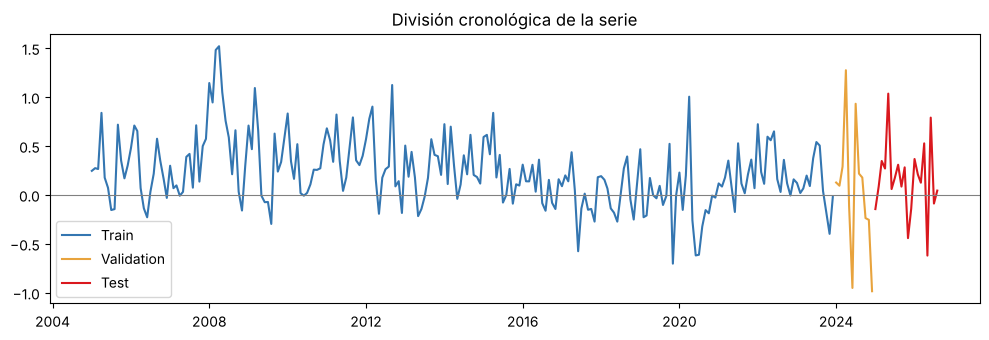

In [21]:
VAL = slice('2024-01', '2024-12')
TEST = slice('2025-01', '2026-08')

print('Train:', len(y.loc[:'2023-12']), '· Validation:', len(y.loc[VAL]), '· Test:', len(y.loc[TEST]))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y.loc[:'2023-12'], color='#3476B1', label='Train')
ax.plot(y.loc[VAL], color='#E8A33D', label='Validation')
ax.plot(y.loc[TEST], color='#DA181E', label='Test')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('División cronológica de la serie')
ax.legend()
plt.show()

## 5.1 Métricas a mano y con scikit-learn

Las mismas del Módulo 3, en puntos porcentuales de inflación:

| Métrica | Fórmula | Pregunta |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum |y-\hat y|$ | ¿cuánto me equivoco normalmente? |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y-\hat y)^2}$ | ¿pesan mucho los errores grandes? |
| **Bias** | $\frac{1}{n}\sum(\hat y-y)$ | ¿pronostico de más o de menos sistemáticamente? |

Primero, a mano para el pronóstico ingenuo en los tres primeros meses de 2024:

In [22]:
tres = pron.loc['2024-01':'2024-03', ['real', 'ingenuo']]
tres['error'] = tres['real'] - tres['ingenuo']
tres['error_abs'] = tres['error'].abs()
tres['error_cuad'] = tres['error'] ** 2
display(tres.round(3))

print('MAE a mano:', round(tres['error_abs'].mean(), 3))
print('RMSE a mano:', round(np.sqrt(tres['error_cuad'].mean()), 3))
print('MAE sklearn:', round(mean_absolute_error(tres['real'], tres['ingenuo']), 3))
print('RMSE sklearn:', round(np.sqrt(mean_squared_error(tres['real'], tres['ingenuo'])), 3))

,real,ingenuo,error,error_abs,error_cuad
fecha,,,,,
2024-01-01,0.125,-0.023,0.149,0.149,0.022
2024-02-01,0.093,0.125,-0.033,0.033,0.001
2024-03-01,0.288,0.093,0.195,0.195,0.038


MAE a mano: 0.125
RMSE a mano: 0.143
MAE sklearn: 0.125
RMSE sklearn: 0.143


In [23]:
def metricas(real, pred):
    """MAE, RMSE y Bias, ignorando los meses sin pronóstico."""
    datos = pd.DataFrame({'real': real, 'pred': pred}).dropna()
    return {
        'MAE': mean_absolute_error(datos['real'], datos['pred']),
        'RMSE': np.sqrt(mean_squared_error(datos['real'], datos['pred'])),
        'Bias': (datos['pred'] - datos['real']).mean(),
        'meses': len(datos),
    }

metodos = ['ingenuo', 'ingenuo_estacional', 'promedio_movil_3', 'media_historica']

tabla_val = pd.DataFrame({m: metricas(pron.loc[VAL, 'real'], pron.loc[VAL, m]) for m in metodos}).T
tabla_val.sort_values('MAE').round(3)

,MAE,RMSE,Bias,meses
ingenuo_estacional,0.408,0.593,0.066,12.0
media_historica,0.482,0.649,0.179,12.0
promedio_movil_3,0.588,0.711,0.074,12.0
ingenuo,0.615,0.838,0.080,12.0


### ¿Qué nos dice Validation (2024)?

- El **ingenuo estacional** tiene el menor MAE (≈ 0.41): en un año con varios choques, copiar el patrón del año anterior funcionó mejor que copiar el mes anterior.
- El **ingenuo** es el peor (≈ 0.62): cada choque de 2024 (abril, junio, julio, diciembre) se trasladó como error al mes siguiente.
- El **RMSE es bastante mayor que el MAE** en todos: unos pocos meses con errores grandes pesan mucho.

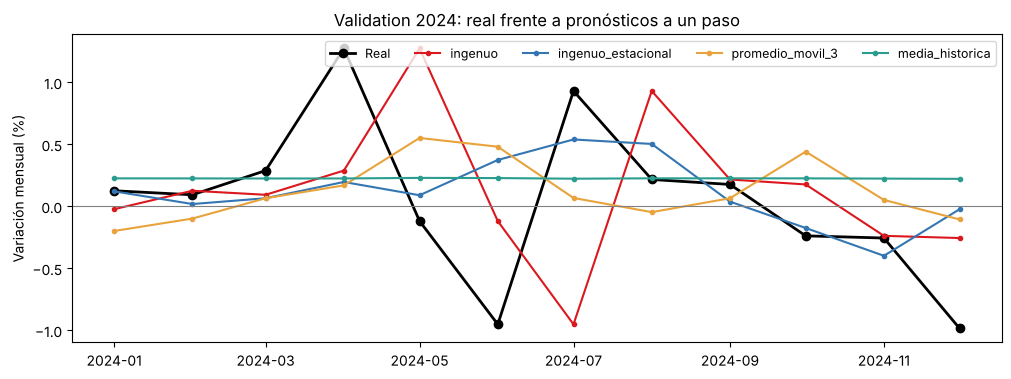

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pron.loc[VAL, 'real'], color='black', marker='o', linewidth=2, label='Real')
for m, color in zip(metodos, ['#DA181E', '#3476B1', '#E8A33D', '#2A9D8F']):
    ax.plot(pron.loc[VAL, m], marker='.', label=m, color=color)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Validation 2024: real frente a pronósticos a un paso')
ax.legend(ncol=5, fontsize=9)
plt.show()

El ingenuo (rojo) dibuja la serie real **desplazada un mes a la derecha**: siempre llega tarde. Es la característica de este método.

## 5.2 Hiperparámetro: la ventana $k$ del promedio móvil

El promedio móvil tiene un hiperparámetro: cuántos meses promediar.

- $k$ pequeño: reacciona rápido, pero copia el ruido (con $k = 1$ es el ingenuo).
- $k$ grande: estable, pero tarda en reaccionar a cambios de nivel.

Probamos $k = 1, \dots, 36$ con un `for` y medimos en **Validation**.

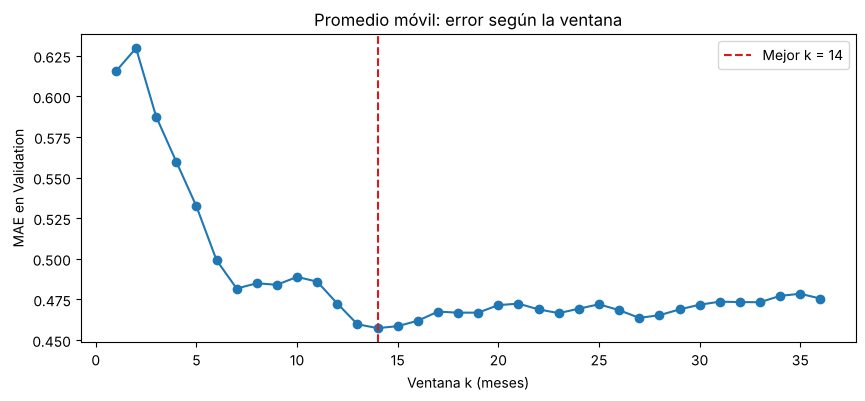

,MAE,RMSE,Bias,meses
k,,,,
1,0.615,0.838,0.080,12
3,0.588,0.711,0.074,12
6,0.499,0.666,0.071,12
12,0.472,0.645,0.089,12
14,0.457,0.634,0.090,12
24,0.469,0.634,0.121,12
36,0.476,0.645,0.156,12


In [25]:
resultados_k = []
for k in range(1, 37):
    pred_k = y.rolling(k).mean().shift(1)
    resultados_k.append({'k': k, **metricas(y.loc[VAL], pred_k.loc[VAL])})

resultados_k = pd.DataFrame(resultados_k)
mejor_k = int(resultados_k.loc[resultados_k['MAE'].idxmin(), 'k'])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(resultados_k['k'], resultados_k['MAE'], marker='o')
ax.axvline(mejor_k, color='#DA181E', linestyle='--', label=f'Mejor k = {mejor_k}')
ax.set_xlabel('Ventana k (meses)')
ax.set_ylabel('MAE en Validation')
ax.set_title('Promedio móvil: error según la ventana')
ax.legend()
plt.show()

resultados_k.set_index('k').loc[[1, 3, 6, 12, mejor_k, 24, 36]].round(3)

El error baja rápido de $k=1$ a $k \approx 7$ y después se estabiliza. El mínimo está en **$k = 14$**, pero entre 12 y 24 la diferencia es de centésimas: **no hay una ventana mágica**. Elegimos $k = 14$ porque es la que minimiza el MAE en Validation, sabiendo que $k = 12$ sería igual de razonable.

Aun con la mejor ventana (MAE ≈ 0.46), el promedio móvil no supera al **ingenuo estacional** en Validation (≈ 0.41).

# 6. Resultado final: Test, una sola vez

Con lo decidido en Validation fijamos los métodos y su configuración. **Ahora** miramos el Test (enero 2025 – agosto 2026) por primera vez, sin cambiar nada después.

In [26]:
pron_final = pronosticos_simples(y, k=mejor_k)
metodos_final = ['ingenuo', 'ingenuo_estacional', f'promedio_movil_{mejor_k}', 'media_historica']

resumen = pd.concat({
    'Validation': pd.DataFrame({m: metricas(pron_final.loc[VAL, 'real'], pron_final.loc[VAL, m]) for m in metodos_final}).T,
    'Test': pd.DataFrame({m: metricas(pron_final.loc[TEST, 'real'], pron_final.loc[TEST, m]) for m in metodos_final}).T,
}, axis=1)

resumen.loc[:, (slice(None), ['MAE', 'RMSE', 'Bias'])].round(3)

Validation                 Test              
                          MAE   RMSE   Bias    MAE   RMSE   Bias
ingenuo                 0.615  0.838  0.080  0.478  0.618 -0.051
ingenuo_estacional      0.408  0.593  0.066  0.501  0.665 -0.029
promedio_movil_14       0.457  0.634  0.090  0.289  0.386 -0.065
media_historica         0.482  0.649  0.179  0.273  0.370  0.053

### Una lección importante: el ganador de Validation no ganó en Test

| Periodo | Mejor método | MAE |
|---|---|---:|
| Validation 2024 | ingenuo estacional | ≈ 0.41 |
| Test 2025–2026 | media histórica | ≈ 0.27 |

En Test, el ingenuo estacional quedó entre los peores (≈ 0.50). ¿Por qué?

- **2024 fue un año atípico** (sección 2.5). En Test, el ingenuo estacional pronostica cada mes de 2025 copiando el mismo mes de 2024, es decir, **copia los choques de 2024**.
- La **media histórica** casi no reacciona a nada: en un periodo tranquilo, pronosticar "lo normal" funciona bien.

Esto no es un fracaso del procedimiento: es exactamente lo que el Test debe revelar. Si hubiéramos elegido mirando el Test, habríamos creído que sabíamos qué método era mejor. **Con 12 meses de Validation, una sola decisión es frágil.** El Día 2 veremos cómo validar con varios cortes (origen móvil) para que la elección sea más estable.

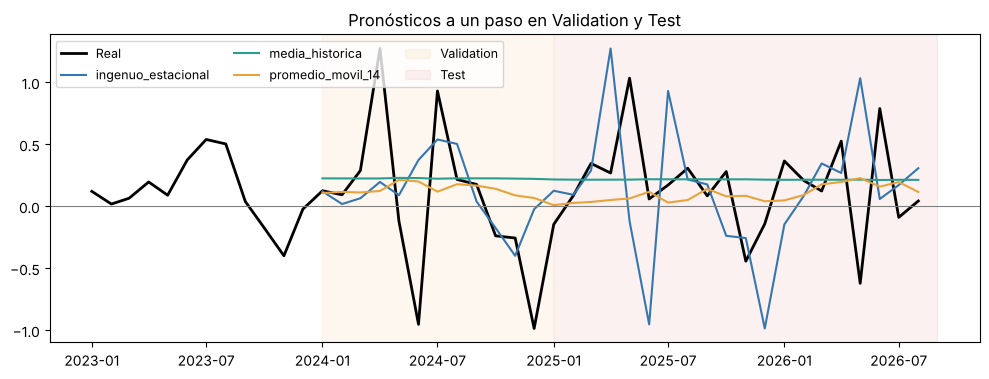

In [27]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.loc['2023-01':], color='black', linewidth=2, label='Real')
for m, color in zip(['ingenuo_estacional', 'media_historica', f'promedio_movil_{mejor_k}'], ['#3476B1', '#2A9D8F', '#E8A33D']):
    ax.plot(pron_final.loc['2024-01':, m], label=m, color=color)
ax.axvspan(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'), color='#E8A33D', alpha=0.08, label='Validation')
ax.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2026-08-31'), color='#DA181E', alpha=0.06, label='Test')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Pronósticos a un paso en Validation y Test')
ax.legend(ncol=3, fontsize=9)
plt.show()

## 6.1 Pronóstico de los próximos tres meses

El último dato es agosto de 2026. ¿Qué dice cada método para septiembre, octubre y noviembre de 2026?

Para el ingenuo, el promedio móvil y la media, el valor se repite en los tres meses: no tenemos los meses intermedios, así que el pronóstico de cada método queda **plano**. El ingenuo estacional sí cambia, porque copia septiembre, octubre y noviembre de 2025.

In [28]:
futuro = pd.date_range('2026-09-01', periods=3, freq='MS')

pronostico_futuro = pd.DataFrame({
    'ingenuo': y.iloc[-1],
    'ingenuo_estacional': y.loc['2025-09':'2025-11'].values,
    f'promedio_movil_{mejor_k}': y.iloc[-mejor_k:].mean(),
    'media_historica': y.mean(),
}, index=futuro)

pronostico_futuro.round(2)

,ingenuo,ingenuo_estacional,promedio_movil_14,media_historica
2026-09-01,0.04,0.08,0.11,0.21
2026-10-01,0.04,0.28,0.11,0.21
2026-11-01,0.04,-0.44,0.11,0.21


Las diferencias entre métodos son de varias décimas: para septiembre de 2026 los pronósticos van desde ≈ 0.04 % hasta ≈ 0.21 %. **Sin un intervalo de confianza no sabemos cuánto confiar en ninguno**; los intervalos llegan con ARIMA el Día 3.

# 7. Comparación final: los mismos métodos en otras series

¿Gana siempre el mismo método? Apliquemos el procedimiento completo a cinco series del BCE, con el mismo corte (Validation 2024, Test desde 2025).

In [29]:
otras = {
    'ipc_var_mensual': '2005',
    'exportaciones_fob_musd': '2005',
    'balanza_comercial_musd': '2005',
    'riesgo_pais_pb': '2005',
    'reservas_internacionales_musd': '2005',
    'tasa_activa_ref_pct': '2015',
}

filas = []
for col, desde in otras.items():
    z = series[col].loc[desde:].dropna()
    p = pronosticos_simples(z, k=mejor_k)
    for m in metodos_final:
        filas.append({'serie': col, 'metodo': m,
                      'MAE_Test': metricas(p.loc['2025-01':, 'real'], p.loc['2025-01':, m])['MAE']})

comparacion = pd.DataFrame(filas).pivot(index='serie', columns='metodo', values='MAE_Test')
comparacion['ganador'] = comparacion.idxmin(axis=1)
comparacion.round(2)

metodo,ingenuo,ingenuo_estacional,media_historica,promedio_movil_14,ganador
serie,,,,,
balanza_comercial_musd,350.36,274.91,430.91,210.45,promedio_movil_14
exportaciones_fob_musd,321.60,312.44,1368.34,265.33,promedio_movil_14
ipc_var_mensual,0.48,0.50,0.27,0.29,media_historica
reservas_internacionales_musd,503.73,2497.79,5244.24,1483.04,ingenuo
riesgo_pais_pb,87.53,523.98,398.28,330.32,ingenuo
tasa_activa_ref_pct,0.19,1.98,0.96,1.28,ingenuo


### ¿Por qué gana un método distinto en cada serie?

- **Riesgo país, reservas y tasa activa** son series **persistentes**: su nivel cambia poco de un mes a otro. El ingenuo gana con amplitud; promediar muchos meses o copiar el año anterior las deja muy lejos del nivel actual.
- **Exportaciones y balanza comercial** son series con ruido mensual alrededor de un nivel que se mueve: promediar varios meses reduce el ruido sin alejarse del nivel.
- **La inflación** oscila alrededor de un promedio bajo: la media histórica es difícil de superar en un periodo tranquilo.

**Conclusión:** no existe un método mejor en general. La autocorrelación y la gráfica de la serie nos dan pistas sobre qué método funcionará, y la validación lo confirma.

> Las métricas están en las unidades de cada serie (puntos básicos, millones de dólares, puntos porcentuales): **no se comparan entre filas**, solo entre columnas de la misma fila.

# 8. Reto de cierre: otra serie, mismo método

En `datos/complementarios/ipc_ecuador_ccif_ciudades_2005_2026.csv` está el IPC por **ciudad** y por **división de consumo** (alimentos, transporte, educación…), en formato largo:

| Columna | Contenido |
|---|---|
| `dominio` | Nacional, RCosta, RSierra o una de 9 ciudades |
| `nivel` | General, División o Grupo |
| `ccif` | código de la clasificación de consumo |
| `descripcion` | nombre de la división o grupo |
| `fecha`, `indice` | mes y valor del índice |

**Tu tarea:** elige una ciudad y una división (por ejemplo, Quito y "Servicios educativos" o Guayaquil y "Alimentos y bebidas no alcohólicas") y repite el procedimiento del día:

1. Filtra la serie y calcula la variación mensual con `pct_change() * 100`.
2. Grafícala, revisa extremos y descompónla con `seasonal_decompose` o `STL`. ¿Tiene más o menos estacionalidad que la inflación general?
3. Calcula la ACF. ¿Qué rezagos sobresalen?
4. Aplica los cuatro pronósticos simples, elige $k$ en Validation y evalúa una sola vez en Test.
5. Escribe tres líneas: qué método ganó, por qué crees que ganó y qué limitación tiene.

In [30]:
# Punto de partida del reto.
ipc_ciudades = pd.read_csv(DATA_DIR / 'complementarios' / 'ipc_ecuador_ccif_ciudades_2005_2026.csv',
                           parse_dates=['fecha'])

print(ipc_ciudades['dominio'].unique())
print(ipc_ciudades.loc[ipc_ciudades['nivel'] == 'División', 'descripcion'].unique())

# Ejemplo de filtro: educación en Quito.
educacion_quito = (
    ipc_ciudades
    .query("dominio == 'Quito' and descripcion == 'Servicios educativos'")
    .set_index('fecha')['indice']
    .asfreq('MS')
)
educacion_quito.tail()

<StringArray>
[     'Ambato',      'Cuenca',  'Esmeraldas',   'Guayaquil',        'Loja',
     'Machala',       'Manta',    'Nacional',       'Quito',      'RCosta',
     'RSierra', 'Sto.Domingo']
Length: 12, dtype: str
<StringArray>
[                                         'Alimentos y bebidas no alcohólicas',
                               'Bebidas alcohólicas, tabaco y estupefacientes',
                                                 'Prendas de vestir y calzado',
                      'Vivienda, agua, electricidad, gas y otros combustibles',
 'Muebles, artículos para el hogar y para la conservación ordinaria del hogar',
                                                                       'Salud',
                                                                  'Transporte',
                                                  'Información y comunicación',
                                               'Recreación, deporte y cultura',
                                              

fecha
2026-02-01    100.206813
2026-03-01    100.206813
2026-04-01    100.206813
2026-05-01    100.206813
2026-06-01    100.206813
Freq: MS, Name: indice, dtype: float64

In [31]:
# A partir de aquí escribe tus propias celdas.

## Checklist para cualquier serie nueva

Antes de pronosticar deberías poder contestar:

- ¿qué representa una fila y cuál es la frecuencia?
- ¿qué periodo representa la economía que quiero pronosticar?
- ¿hay tendencia? ¿cambia con el tiempo?
- ¿hay estacionalidad? ¿en qué meses?
- ¿qué meses son atípicos y qué pasó en ellos?
- ¿qué rezagos tienen autocorrelación fuera de la banda?
- ¿qué método simple es la línea base a superar?
- ¿separé Train, Validation y Test **por fecha**, y miré el Test una sola vez?

**Puente hacia el Día 2:** hoy evaluamos con un solo corte y vimos que la decisión fue frágil. Mañana aprenderemos a validar con varios cortes, a distinguir horizontes de pronóstico y a preparar la serie para los modelos AR, MA y ARIMA.